In [1]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

n_rc=20
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 10, 10
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.1 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 3. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.5 * nS 
g_AMPA_rec_E = 5.5 * nS 
g_AMPA_ext_I = 5.5 * nS
g_AMPA_rec_I = 5.5 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms



#STDP/iSTDP
Apre   =  0.0025
Apost  = -0.0030
w_max = 1.0 #1.5

Apre_i  = -0.0010
Apost_i =  0.0012
w_max_i = 1.0


tau_HSP = 100*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second
  

recurrent_radius = 2


kill_mask = np.ones(400, dtype=np.float32)
# kill_mask[np.array([range(45,47),range(35,37),range(55,57)]).flatten()]=0
# pen_idx = np.concatenate([range(24,28),[34,38,44,48,54,58],range(41,68)])
# far_idx = np.concatenate([range(1,18),range(71,99)])

# kill_mask[range(32,37)]=0 
# pen_idx = np.concatenate([range(21,28),[31,38],range(41,48)])
# far_idx = np.concatenate([range(1,18),range(71,99)])

# kill_mask[np.array([range(42,47),range(32,37)]).flatten()]=0
# pen_idx = np.concatenate([range(21,28),[31,38,41,48],range(51,58)])
# far_idx = np.concatenate([range(1,18),range(71,99)])

# kill_mask[55]=0
# core_idx = np.where(kill_mask == 0)[0]          


def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA):
    # variables
    n_input_rows = 20  
    n_input_columns = 20 
    n_output_rows = 20 
    n_output_columns = 20
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 10, 10
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn ) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E  * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * k_AMPA_E_hsp  * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E * k_GABA_E_hsp * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dk_AMPA_E_hsp/dt = ((1 - k_AMPA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_ins_AMPA_E
                - (k_AMPA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_int_AMPA_E) : 1

    dk_GABA_E_hsp/dt = (-(k_GABA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_int_GABA_E
                + (1 - k_GABA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * 0.3 * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * 0.3 * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz


    dy_act / dt = -y_act / tau_active : 1
    '''


    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler',name='P_E')
    P_E.v = V_L
    P_E.k_AMPA_E_hsp = 0.35  
    P_E.k_GABA_E_hsp = 0.35  
    P_E.tau_ins_AMPA_E = tau_ins_AMPA   #50'000
    P_E.tau_int_AMPA_E = tau_int_AMPA   #5'000
    P_E.tau_ins_GABA_E = tau_ins_GABA   
    P_E.tau_int_GABA_E = tau_int_GABA  

    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler',name='P_I')
    P_I.v = V_L


    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    
    C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
        s_AMPA_ext += w  
        ''', method='euler', name='PG_E')
    C_PG_E.connect(j='i')  

    
    C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
        s_AMPA += w  
        ''', method='euler', name='E_E')
    recurrent_radius = 2
    for y1 in range(n_output_rows):
        for x1 in range(n_output_columns):
            post = y1 * n_output_columns + x1
            for dy in range(-recurrent_radius, recurrent_radius + 1):
                for dx in range(-recurrent_radius, recurrent_radius + 1):
                    if dx == 0 and dy == 0:
                        continue
                    x2 = x1 + dx
                    y2 = y1 + dy
                    if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                        pre = y2 * n_output_columns + x2
                        C_E_E.connect(i=pre, j=post)
    C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
    s_AMPA += w
    ''', method='euler', name='E_I') #        x_postE_post += 1.0 
    C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
    for inh_idx, (ix, iy) in enumerate(inh_positions):
        for ex_y in range(n_output_rows):
            for ex_x in range(n_output_columns):
                if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                    exc_idx = ex_y * n_output_columns + ex_x
                    C_I_E.connect(i=inh_idx, j=exc_idx)
                    C_E_I.connect(i=exc_idx, j=inh_idx)
    C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
    for iy in range(n_inh_rows):
        for ix in range(n_inh_cols):
            post = iy * n_inh_cols + ix
            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    if dx == 0 and dy == 0:
                        continue
                    x2, y2 = ix + dx, iy + dy
                    if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                        pre = y2 * n_inh_cols + x2
                        C_I_I.connect(i=pre, j=post)



    C_PG_E.w[:] = 1.1 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
    C_I_E.w[:] = np.clip(np.random.normal(loc=0.42, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
    C_I_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
    C_E_I.w[:] = 0.8#np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I
    C_E_E.w[:] = np.clip(np.random.normal(loc=0.32, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

    # rate_core = NeuronGroup(1, 'r_core : Hz', method='euler', name='rate_core')
    # rate_pen  = NeuronGroup(1, 'r_pen  : Hz', method='euler', name='rate_pen')
    # rate_far  = NeuronGroup(1, 'r_far  : Hz', method='euler', name='rate_far')
    # # Core
    # C_r_core = Synapses(
    #     P_E, rate_core,
    #     model=''' N_core : 1
    #     r_core_post = r_est_pre / N_core : Hz (summed)''',
    #     method='euler',
    #     name='C_r_core'
    # )
    # C_r_core.connect(i=core_idx, j=0)
    # C_r_core.N_core = len(core_idx)
    # # Penumbra
    # C_r_pen = Synapses(
    #     P_E, rate_pen,
    #     model='''N_pen : 1
    #     r_pen_post = r_est_pre / N_pen : Hz (summed)''',
    #     method='euler',
    #     name='C_r_pen'
    # )
    # C_r_pen.connect(i=pen_idx, j=0)
    # C_r_pen.N_pen= len(pen_idx)
    # # Far
    # C_r_far = Synapses(
    #     P_E, rate_far,
    #     model='''N_far : 1
    #     r_far_post = r_est_pre / N_far : Hz (summed)''',
    #     method='euler',
    #     name='C_r_far'
    # )
    # C_r_far.connect(i=far_idx, j=0)
    # C_r_far.N_far=len(far_idx)
    
    # rate_core_mon = StateMonitor(rate_core, 'r_core', record=True, dt=record_dt, name='rate_core_mon')
    # rate_pen_mon  = StateMonitor(rate_pen,  'r_pen',  record=True, dt=record_dt, name='rate_pen_mon')
    # rate_far_mon  = StateMonitor(rate_far,  'r_far',  record=True, dt=record_dt, name='rate_far_mon')
    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'k_AMPA_E_hsp', record=True, dt=record_dt, name='k_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'k_GABA_E_hsp', record=True, dt=record_dt, name='k_GABA_E_hsp')

    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')


    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_rand_rate(net, show_time = 1000*ms):
    N_inp=net['inp'].N
    rates = np.random.normal(loc=40, scale=3, size=N_inp)
    rates *= kill_mask
    rate_img = np.clip(rates, 5, 50)*Hz
    net['inp'].rates = rate_img
    net.run(show_time, report = 'text')



def run_sim(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA,show_time = 1000*ms):
    net = build_network(tau_ins_AMPA=tau_ins_AMPA,tau_int_AMPA=tau_int_AMPA,tau_ins_GABA=tau_ins_GABA,tau_int_GABA=tau_int_GABA)
    show_rand_rate(net,show_time=show_time)
    return net



INFO       Cache size for target 'cython': 2296 MB.
You can call clear_cache('cython') to delete all files from the cache or manually delete files in the '/home/vincent/.cython/brian_extensions' directory. [brian2]


In [2]:
start_scope()
seed(1234)
defaultclock.dt = 1000 * us
net = run_sim(tau_ins_AMPA=50*second,
              tau_int_AMPA=50*second,
              tau_ins_GABA=50*second,
              tau_int_GABA=50*second,
              show_time=1000*second)

INFO:root:creating /tmp/brian_flag_test_uaosjcdt/tmp
INFO:root:creating /tmp/brian_flag_test_uaosjcdt/tmp/brian_flag_test_uaosjcdt
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_uaosjcdt/flag_test.cpp -o /tmp/brian_flag_test_uaosjcdt/tmp/brian_flag_test_uaosjcdt/flag_test.o -w
INFO:root:creating /tmp/brian_flag_test_3ocv0y38/tmp
INFO:root:creating /tmp/brian_flag_test_3ocv0y38/tmp/brian_flag_test_3ocv0y38
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_3ocv0y38/flag_test.cpp -o /tmp/brian_flag_test_3ocv0y38/tmp/brian_flag_test_3ocv0y38/flag_test.o -O3
INFO:root:creating /tmp/brian_flag_test_25kbpcni/tmp
INFO:root:creating /tmp/brian_flag_test_25kbpcni/tmp/brian_flag_test_25kbpcni
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_25kbpcni/flag_test.cpp -o /tmp/brian_flag_test_25

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s


WARNING    'rates' is an internal variable of group 'inp', but also exists in the run namespace with the value array([45.62409642, 42.39579307, 43.39614801, ..., 41.04115769,
       45.22666804, 44.24807434]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Starting simulation at t=0. s for a duration of 1. ks
128.129 s (12%) simulated in 10s, estimated 1m 8s remaining.
263.644 s (26%) simulated in 20s, estimated 56s remaining.
0.395921 ks (39%) simulated in 30s, estimated 46s remaining.
0.526931 ks (52%) simulated in 40s, estimated 36s remaining.
0.664424 ks (66%) simulated in 50s, estimated 25s remaining.
0.796928 ks (79%) simulated in 1m 0s, estimated 15s remaining.
0.928133 ks (92%) simulated in 1m 10s, estimated 5s remaining.
1. ks (100%) simulated in 1m 15s


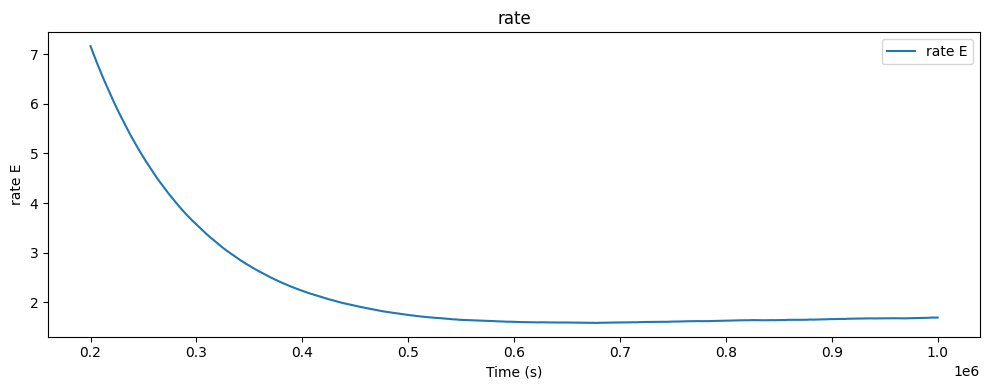

In [3]:
r_est_E = net['rate_pop_mon_E']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[1000:]/ms, r_est_E.r_pop_E[0,1000:]/Hz, color='tab:blue', label='rate E')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

In [4]:
net.store('baseline')

In [5]:
def hsp_sigmoid(x):
    return 1.0 / (1.0 + np.exp(-15.0 * x))

def hsp_func(rate_hz, kE, kI,
            target_hz=2.0,
            tau_ins_AMPA_s=500.0,
            tau_int_AMPA_s=500.0,
            tau_ins_GABA_s=500.0,
            tau_int_GABA_s=500.0):

    x_up = (target_hz - rate_hz) / target_hz - 0.5
    x_down = (rate_hz - target_hz) / target_hz - 0.5

    s_up = hsp_sigmoid(x_up)
    s_down = hsp_sigmoid(x_down)

    dkE = (1.0 - kE) * s_up / tau_ins_AMPA_s - kE * s_down / tau_int_AMPA_s
    dkI = -kI * s_up / tau_int_GABA_s + (1.0 - kI) * s_down / tau_ins_GABA_s

    return dkE, dkI

# net = build_network(tau_ins_AMPA=500.0*second,tau_int_AMPA=500.0*second,tau_ins_GABA=500.0*second,tau_int_GABA=500.0*second)
# net.store('baseline')
# net.restore('baseline')

In [11]:
def eval_phase_point(net, kE, kI, alpha=1.0, run_time=10*second):
    net.restore('baseline')

    P_E = net['P_E']
    C_PG_E = net['PG_E']
    rate_mon_E = net['rate_pop_mon_E']

    # HSP values
    P_E.k_AMPA_E_hsp = kE
    P_E.k_GABA_E_hsp = kI

    # HSP inf
    P_E.tau_ins_AMPA_E = 1e20 * second
    P_E.tau_int_AMPA_E = 1e20 * second
    P_E.tau_ins_GABA_E = 1e20 * second
    P_E.tau_int_GABA_E = 1e20 * second

    #scotoma/small undercut
    baseline_w = float(C_PG_E.w[0])
    C_PG_E.w[:] = alpha * baseline_w

    net.run(run_time, report='text')

    r_trace_hz = np.array(rate_mon_E.r_pop_E[0] / Hz)
    max_rate_hz = np.max(r_trace_hz)
    mean_rate_hz = np.mean(r_trace_hz)

    return max_rate_hz, mean_rate_hz, r_trace_hz

In [12]:
kE_vals = np.linspace(0.0, 1.0, 11)
kI_vals = np.linspace(0.0, 1.0, 11)

max_rate_map = np.zeros((len(kI_vals), len(kE_vals)))
mean_rate_map = np.zeros((len(kI_vals), len(kE_vals)))
dkE_map = np.zeros((len(kI_vals), len(kE_vals)))
dkI_map = np.zeros((len(kI_vals), len(kE_vals)))

alpha = 1.0   

for i, kI in enumerate(kI_vals):
    for j, kE in enumerate(kE_vals):

        max_r, mean_r, r_trace = eval_phase_point(
            net,
            kE=kE,
            kI=kI,
            alpha=alpha,
            run_time=5*second
        )

        max_rate_map[i, j] = max_r
        mean_rate_map[i, j] = mean_r

        dkE, dkI = hsp_func(
            rate_hz=mean_r,   
            kE=kE,
            kI=kI,
            target_hz=2.0,
            tau_ins_AMPA_s=500.0,
            tau_int_AMPA_s=500.0,
            tau_ins_GABA_s=500.0,
            tau_int_GABA_s=500.0
        )

        dkE_map[i, j] = dkE
        dkI_map[i, j] = dkI

Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated 

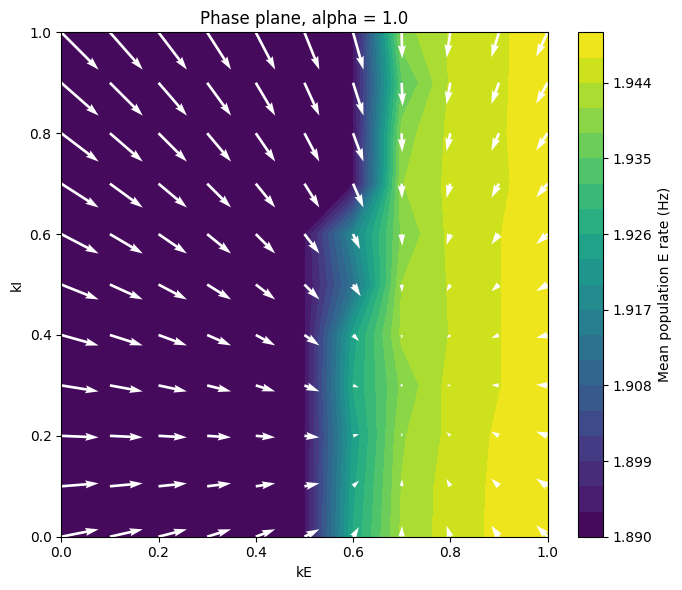

In [15]:
import matplotlib.pyplot as plt

KE, KI = np.meshgrid(kE_vals, kI_vals)

plt.figure(figsize=(7,6))
plt.contourf(KE, KI, mean_rate_map, levels=20)
plt.colorbar(label='Mean population E rate (Hz)')

plt.quiver(KE, KI, dkE_map, dkI_map, color='white')

plt.xlabel('kE')
plt.ylabel('kI')
plt.title(f'Phase plane, alpha = {alpha}')
plt.tight_layout()
plt.show()

In [16]:
kE_vals = np.linspace(0.0, 1.0, 11)
kI_vals = np.linspace(0.0, 1.0, 11)

max_rate_map = np.zeros((len(kI_vals), len(kE_vals)))
mean_rate_map = np.zeros((len(kI_vals), len(kE_vals)))
dkE_map = np.zeros((len(kI_vals), len(kE_vals)))
dkI_map = np.zeros((len(kI_vals), len(kE_vals)))

alpha = 0.9   

for i, kI in enumerate(kI_vals):
    for j, kE in enumerate(kE_vals):

        max_r, mean_r, r_trace = eval_phase_point(
            net,
            kE=kE,
            kI=kI,
            alpha=alpha,
            run_time=5*second
        )

        max_rate_map[i, j] = max_r
        mean_rate_map[i, j] = mean_r

        dkE, dkI = hsp_func(
            rate_hz=mean_r,   
            kE=kE,
            kI=kI,
            target_hz=2.0,
            tau_ins_AMPA_s=500.0,
            tau_int_AMPA_s=500.0,
            tau_ins_GABA_s=500.0,
            tau_int_GABA_s=500.0
        )

        dkE_map[i, j] = dkE
        dkI_map[i, j] = dkI

Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in < 1s
Starting simulation at t=1. ks for a duration of 5. s
5. s (100%) simulated in

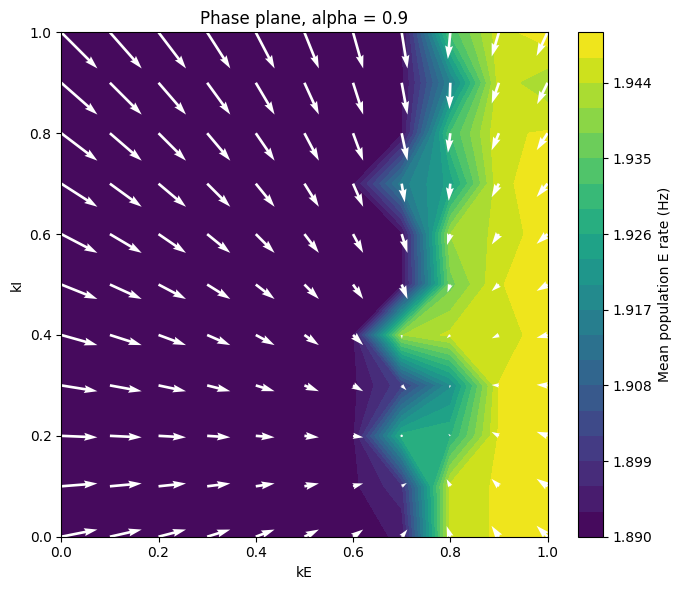

In [60]:
import matplotlib.pyplot as plt

KE, KI = np.meshgrid(kE_vals, kI_vals)

plt.figure(figsize=(7,6))
plt.contourf(KE, KI, mean_rate_map, levels=20)
plt.colorbar(label='Mean population E rate (Hz)')

plt.quiver(KE, KI, dkE_map, dkI_map, color='white')

plt.xlabel('kE')
plt.ylabel('kI')
plt.title(f'Phase plane, alpha = {alpha}')
plt.tight_layout()
plt.show()

In [6]:
def run_alpha_hsp(net, alpha=1.0, run_time=1000*second,analysis_start_s=1000*second):
    net.restore('baseline')

    PG_E = net['PG_E']
    rate_mon_E = net['rate_pop_mon_E']

    baseline_w = float(PG_E.w[0])
    PG_E.w[:] = alpha * baseline_w

    net.run(run_time, report='text')
    t=rate_mon_E.t
    mask = t >= analysis_start_s

    return {
        'alpha': alpha,
        't': np.array(rate_mon_E.t[mask] / second),
        'r': np.array(rate_mon_E.r_pop_E[0,mask] / Hz),
    }


def classify_cyclic_bursting_from_trace(t, r, threshold_hz=3.0, min_duration_s=1.0):

    t = np.asarray(t)
    r = np.asarray(r)

    above = (r > threshold_hz)

    if len(t) < 2:
        return {
            'frac_above_thresh': 0.0,
            'n_episodes': 0,
            'mean_episode_duration': 0.0,
            'max_episode_duration': 0.0,
            'is_cyclic_bursting': False
        }

    dt = np.median(np.diff(t))

    frac_above = np.mean(above)

    # find contiguous "above threshold" segments
    episodes = []
    in_ep = False
    start_idx = None

    for i, val in enumerate(above):
        if val and not in_ep:
            in_ep = True
            start_idx = i
        elif not val and in_ep:
            end_idx = i - 1
            dur = (end_idx - start_idx + 1) * dt
            if dur >= min_duration_s:
                episodes.append(dur)
            in_ep = False

    # if trace ends while still above threshold
    if in_ep:
        end_idx = len(above) - 1
        dur = (end_idx - start_idx + 1) * dt
        if dur >= min_duration_s:
            episodes.append(dur)

    n_episodes = len(episodes)
    mean_episode_duration = float(np.mean(episodes)) if episodes else 0.0
    max_episode_duration = float(np.max(episodes)) if episodes else 0.0

    # simple first-pass rule:
    # cyclic bursting = repeated episodes + nontrivial time above threshold
    is_cyclic_bursting = (n_episodes >= 3) and (frac_above >= 0.1)

    return {
        'frac_above_thresh': float(frac_above),
        'n_episodes': n_episodes,
        'mean_episode_duration': mean_episode_duration,
        'max_episode_duration': max_episode_duration,
        'is_cyclic_bursting': is_cyclic_bursting
    }

In [53]:
sim=run_alpha_hsp(net,0.9,1000*second)

Starting simulation at t=1. ks for a duration of 1. ks
91.843 s (9%) simulated in 10s, estimated 1m 39s remaining.
201.356 s (20%) simulated in 20s, estimated 1m 19s remaining.
293.231 s (29%) simulated in 30s, estimated 1m 12s remaining.
0.362664 ks (36%) simulated in 40s, estimated 1m 10s remaining.
0.442725 ks (44%) simulated in 50s, estimated 1m 3s remaining.
0.52367 ks (52%) simulated in 1m 0s, estimated 55s remaining.
0.60106 ks (60%) simulated in 1m 10s, estimated 47s remaining.
0.703667 ks (70%) simulated in 1m 20s, estimated 34s remaining.
0.82217 ks (82%) simulated in 1m 30s, estimated 19s remaining.
0.907326 ks (90%) simulated in 1m 40s, estimated 10s remaining.
0.977983 ks (97%) simulated in 1m 50s, estimated 2s remaining.
1. ks (100%) simulated in 1m 52s


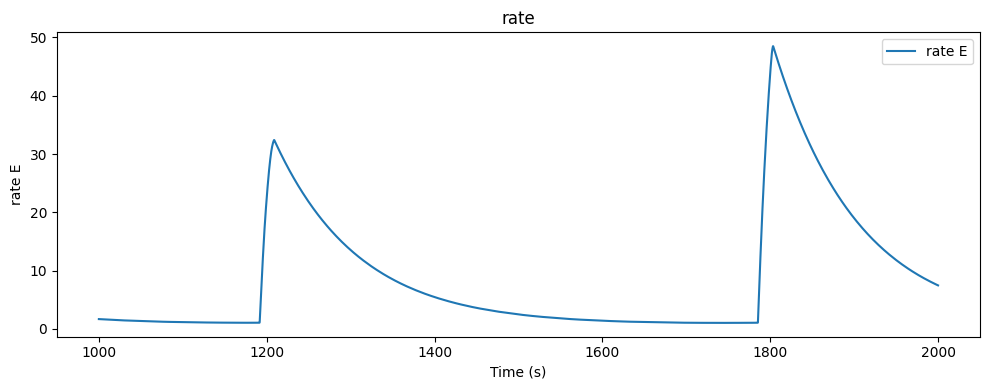

In [54]:
plt.figure(figsize=(10, 4))
plt.plot(sim['t'], sim['r'], color='tab:blue', label='rate E')
plt.xlabel('Time (s)')
plt.ylabel('rate E')
plt.title('rate')
plt.legend()
plt.tight_layout()

In [7]:
def classify_cyclic_bursting_from_trace(t, r,
                                        threshold_hz=4.0,
                                        min_duration_s=2.0):


    t = np.asarray(t)
    r = np.asarray(r)

    if len(t) < 2:
        return {
            'frac_above_thresh': 0.0,
            'n_episodes': 0,
            'mean_episode_duration': 0.0,
            'max_episode_duration': 0.0,
            'is_cyclic_bursting': False
        }

    above = (r > threshold_hz)
    dt = np.median(np.diff(t))

    frac_above = np.mean(above)

    episodes = []
    in_ep = False
    start_idx = None

    for i, val in enumerate(above):
        if val and not in_ep:
            in_ep = True
            start_idx = i
        elif (not val) and in_ep:
            end_idx = i - 1
            dur = (end_idx - start_idx + 1) * dt
            if dur >= min_duration_s:
                episodes.append(dur)
            in_ep = False

    if in_ep:
        end_idx = len(above) - 1
        dur = (end_idx - start_idx + 1) * dt
        if dur >= min_duration_s:
            episodes.append(dur)

    n_episodes = len(episodes)
    mean_episode_duration = float(np.mean(episodes)) if episodes else 0.0
    max_episode_duration = float(np.max(episodes)) if episodes else 0.0

    is_cyclic_bursting = (n_episodes >= 2) and (frac_above >= 0.1)

    return {
        'frac_above_thresh': float(frac_above),
        'n_episodes': n_episodes,
        'mean_episode_duration': mean_episode_duration,
        'max_episode_duration': max_episode_duration,
        'is_cyclic_bursting': is_cyclic_bursting
    }

In [8]:
def scan_alpha_bifurcation(net, alpha_vals, run_time=1000*second,
                           threshold_hz=4.0, min_duration_s=2.0):

    results = []

    for alpha in alpha_vals:
        #print(f"alpha={alpha}")
        sim = run_alpha_hsp(net, alpha=alpha, run_time=run_time, analysis_start_s=1000*second)

        cls = classify_cyclic_bursting_from_trace(
            t=sim['t'],
            r=sim['r'],
            threshold_hz=threshold_hz,
            min_duration_s=min_duration_s
        )

        results.append({
            'alpha': alpha,
            'frac_above_thresh': cls['frac_above_thresh'],
            'n_episodes': cls['n_episodes'],
            'mean_episode_duration': cls['mean_episode_duration'],
            'max_episode_duration': cls['max_episode_duration'],
            'is_cyclic_bursting': cls['is_cyclic_bursting'],
            'sim': sim
        })

        print(
            f"alpha={alpha:.3f} | "
            f"frac_above={cls['frac_above_thresh']:.3f} | "
            f"episodes={cls['n_episodes']} | "
            f"cyclic={cls['is_cyclic_bursting']}"
        )

    return results

Starting simulation at t=1. ks for a duration of 2. ks
83.454 s (4%) simulated in 10s, estimated 3m 50s remaining.
165.543 s (8%) simulated in 20s, estimated 3m 42s remaining.
250.394 s (12%) simulated in 30s, estimated 3m 30s remaining.
0.341101 ks (17%) simulated in 40s, estimated 3m 15s remaining.
0.422723 ks (21%) simulated in 50s, estimated 3m 7s remaining.
0.499611 ks (24%) simulated in 1m 0s, estimated 3m 0s remaining.
0.573595 ks (28%) simulated in 1m 10s, estimated 2m 54s remaining.
0.651107 ks (32%) simulated in 1m 20s, estimated 2m 46s remaining.
0.729634 ks (36%) simulated in 1m 30s, estimated 2m 37s remaining.
0.805498 ks (40%) simulated in 1m 40s, estimated 2m 28s remaining.
0.885295 ks (44%) simulated in 1m 50s, estimated 2m 19s remaining.
0.965718 ks (48%) simulated in 2m 0s, estimated 2m 9s remaining.
1.047705 ks (52%) simulated in 2m 10s, estimated 1m 58s remaining.
1.141303 ks (57%) simulated in 2m 20s, estimated 1m 45s remaining.
1.235793 ks (61%) simulated in 2m 30

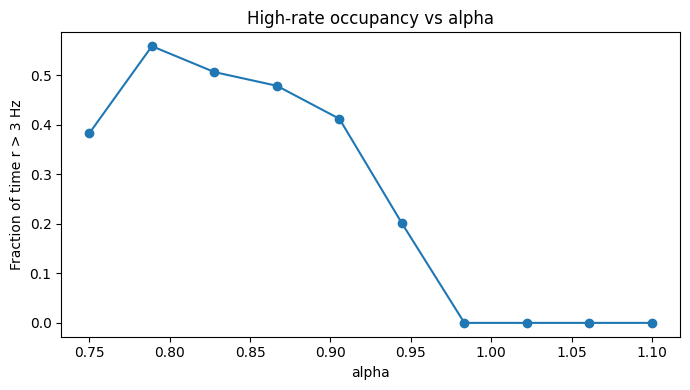

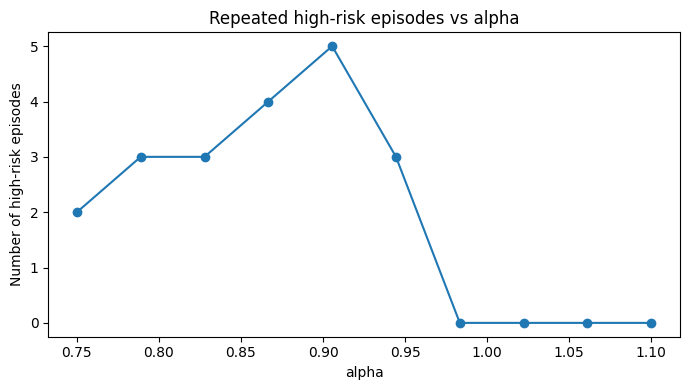

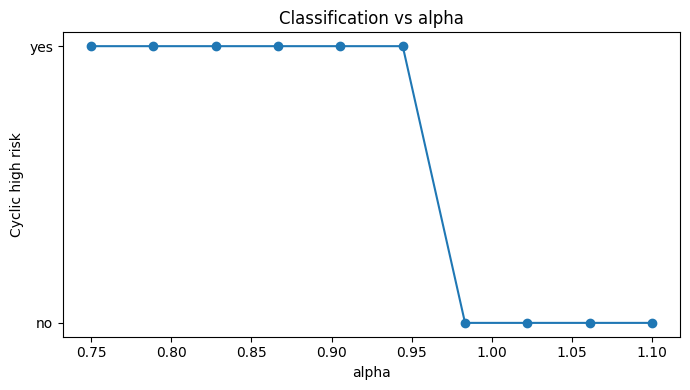

In [10]:
alpha_vals=np.linspace(0.75,1.1,10)
results=scan_alpha_bifurcation(net,alpha_vals=alpha_vals,run_time=2000*second)

alphas = np.array([x['alpha'] for x in results])
frac_above = np.array([x['frac_above_thresh'] for x in results])
n_episodes = np.array([x['n_episodes'] for x in results])
cyclic = np.array([1 if x['is_cyclic_bursting'] else 0 for x in results])

plt.figure(figsize=(7,4))
plt.plot(alphas, frac_above, 'o-')
plt.xlabel('alpha')
plt.ylabel('Fraction of time r > 3 Hz')
plt.title('High-rate occupancy vs alpha')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,4))
plt.plot(alphas, n_episodes, 'o-')
plt.xlabel('alpha')
plt.ylabel('Number of high-risk episodes')
plt.title('Repeated high-risk episodes vs alpha')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,4))
plt.plot(alphas, cyclic, 'o-')
plt.yticks([0,1], ['no','yes'])
plt.xlabel('alpha')
plt.ylabel('Cyclic high risk')
plt.title('Classification vs alpha')
plt.tight_layout()
plt.show()

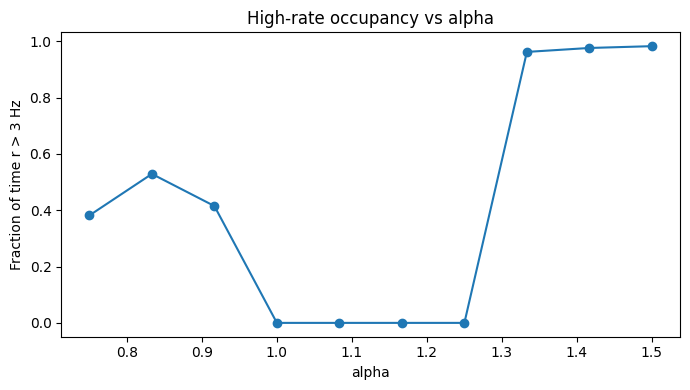

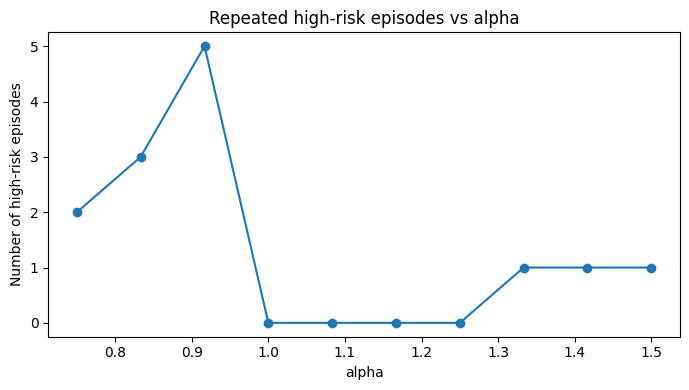

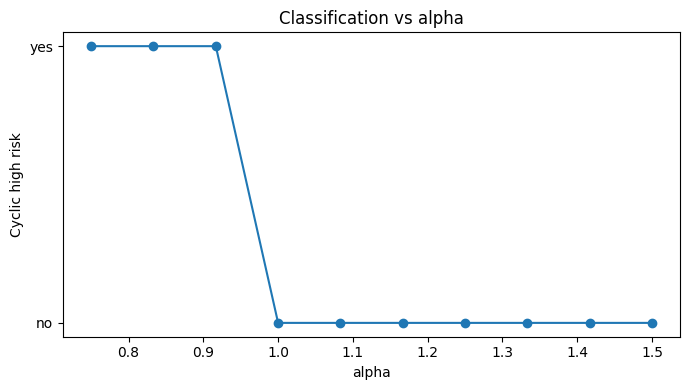

In [ ]:
alpha_vals=np.linspace(0.75,1.5,10)
results=scan_alpha_bifurcation(net,alpha_vals=alpha_vals,run_time=2000*second)

alphas = np.array([x['alpha'] for x in results])
frac_above = np.array([x['frac_above_thresh'] for x in results])
n_episodes = np.array([x['n_episodes'] for x in results])
cyclic = np.array([1 if x['is_cyclic_bursting'] else 0 for x in results])

plt.figure(figsize=(7,4))
plt.plot(alphas, frac_above, 'o-')
plt.xlabel('alpha')
plt.ylabel('Fraction of time r > 4 Hz')
plt.title('High-rate occupancy vs alpha')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,4))
plt.plot(alphas, n_episodes, 'o-')
plt.xlabel('alpha')
plt.ylabel('Number of high-risk episodes')
plt.title('Repeated high-risk episodes vs alpha')
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,4))
plt.plot(alphas, cyclic, 'o-')
plt.yticks([0,1], ['no','yes'])
plt.xlabel('alpha')
plt.ylabel('Cyclic high risk')
plt.title('Classification vs alpha')
plt.tight_layout()
plt.show()